In [6]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [7]:
# Performing First Look ritual

df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
# Checking Datatypes separately

df.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [9]:
# Checking Missing Values

print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [10]:
# Checking columns

print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [11]:
# Scaling: Annual Income (k$) & Spending Score (1-100)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled = scaler.fit_transform(df[['Annual Income (k$)','Spending Score (1-100)']])
df_scaled = pd.DataFrame(scaled, columns=['Annual Income (k$)','Spending Score (1-100)'])
df_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


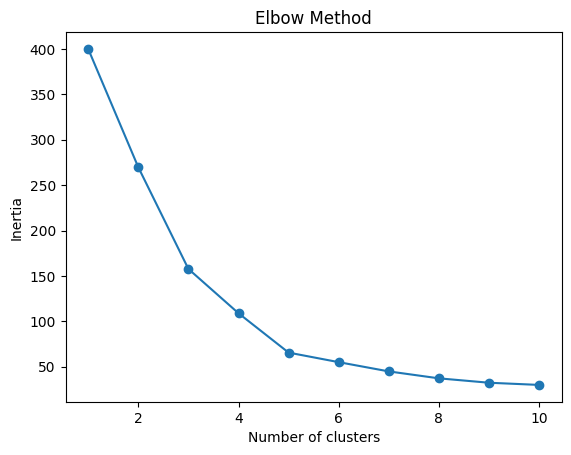

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []
K_Range = range(1, 11)

for k in K_Range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(df_scaled)
  inertias.append(kmeans.inertia_)

plt.plot(K_Range, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

In [13]:
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df_scaled['cluster'] = km.fit_predict(df_scaled)
df_scaled.head()

,Annual Income (k$),Spending Score (1-100),cluster
0,-1.738999,-0.434801,4
1,-1.738999,1.195704,2
2,-1.700830,-1.715913,4
3,-1.700830,1.040418,2
4,-1.662660,-0.395980,4


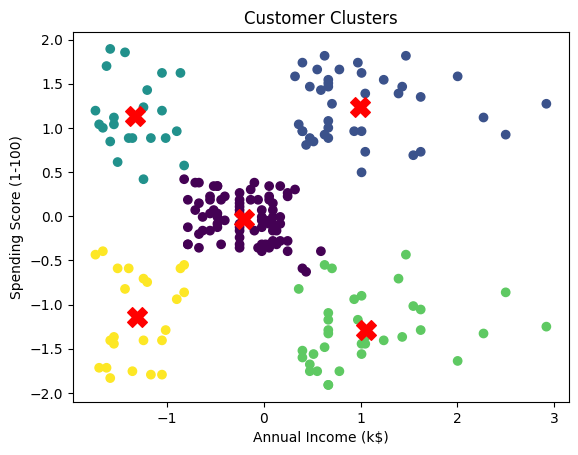

In [14]:
plt.scatter(df_scaled['Annual Income (k$)'], df_scaled['Spending Score (1-100)'], c=df_scaled['cluster'], cmap='viridis')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], color='red', marker='X', s=200, label = 'Centers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Clusters')
plt.show()

In [15]:
# Personas

grouped = df_scaled.groupby('cluster')[['Annual Income (k$)','Spending Score (1-100)']].mean()
print(grouped)

         Annual Income (k$)  Spending Score (1-100)
cluster                                            
0                 -0.200913               -0.026456
1                  0.991583                1.239503
2                 -1.329545                1.132178
3                  1.055003               -1.284439
4                 -1.307519               -1.136965


In [16]:
persona = {
    0: 'Average',
    1: 'High Income, High Spendings',
    2: 'Low Income, High Spendings',
    3: 'High Income, Low Spendings',
    4: 'Low Income, Low Spendings'
}

df_scaled['personas'] = df_scaled['cluster'].map(persona)
df_scaled.head()

,Annual Income (k$),Spending Score (1-100),cluster,personas
0,-1.738999,-0.434801,4,"Low Income, Low Spendings"
1,-1.738999,1.195704,2,"Low Income, High Spendings"
2,-1.700830,-1.715913,4,"Low Income, Low Spendings"
3,-1.700830,1.040418,2,"Low Income, High Spendings"
4,-1.662660,-0.395980,4,"Low Income, Low Spendings"
